In [88]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/SICAPv2/readme.txt
/kaggle/input/SICAPv2/wsi_labels.xlsx
/kaggle/input/SICAPv2/images/16B0006669_Block_Region_24_6_2_xini_14275_yini_13598.jpg
/kaggle/input/SICAPv2/images/18B0005230E_Block_Region_5_11_23_xini_38257_yini_96363.jpg
/kaggle/input/SICAPv2/images/18B0006621D_Block_Region_2_1_13_xini_21582_yini_66086.jpg
/kaggle/input/SICAPv2/images/18B0006177A_Block_Region_2_6_19_xini_51693_yini_147491.jpg
/kaggle/input/SICAPv2/images/16B0022612_Block_Region_1_20_12_xini_15667_yini_92428.jpg
/kaggle/input/SICAPv2/images/17B0035220_Block_Region_5_22_18_xini_39584_yini_76503.jpg
/kaggle/input/SICAPv2/images/16B0022615_Block_Region_4_19_41_xini_44968_yini_22920.jpg
/kaggle/input/SICAPv2/images/17B0034247_Block_Region_2_21_7_xini_39052_yini_24363.jpg
/kaggle/input/SICAPv2/images/18B0005478I_Block_Region_2_13_11_xini_19020_yini_148142.jpg
/kaggle/input/SICAPv2/images/17B0027608_Block_Region_7_16_43_xini_59764_yini_61267.jpg
/kaggle/input/SICAPv2/images/16B0026792_Block_Region_0_11

In [89]:
import tensorflow as tf
print("TF version:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices('GPU'))


TF version: 2.18.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [90]:
!pip install vit-keras scikit-learn seaborn

In [91]:
from pathlib import Path

# 1) See what folder name Kaggle gave your dataset
print("Contents of /kaggle/input:")
!ls /kaggle/input

# Suppose you see a folder like: sicapv2-images
SICAP_ROOT = Path("/kaggle/input/") / "SICAPv2"
  # <-- use the exact folder name you see

# If you open it and see another inner folder (e.g. SICAPv2), then do:
# SICAP_ROOT = Path("/kaggle/input/sicapv2-images") / "SICAPv2"

IMAGES_DIR = SICAP_ROOT / "images"
PARTITION_DIR = SICAP_ROOT / "partition"

print("Images dir:", IMAGES_DIR)
print("Partition dir:", PARTITION_DIR)

print("SICAP_ROOT exists:", SICAP_ROOT.exists())
!ls "{SICAP_ROOT}"


Contents of /kaggle/input:
SICAPv2
Images dir: /kaggle/input/SICAPv2/images
Partition dir: /kaggle/input/SICAPv2/partition
SICAP_ROOT exists: True
images	masks  partition  readme.txt  wsi_labels.xlsx


In [92]:
print("Partition dir:", PARTITION_DIR)
!ls "{PARTITION_DIR}"


Partition dir: /kaggle/input/SICAPv2/partition
Test  Validation


In [93]:
# from pathlib import Path

# SICAP_ROOT = Path("/kaggle/input/sicapv2") / "SICAPv2"
# VAL_ROOT   = SICAP_ROOT / "partition" / "Validation"

# print("VAL_ROOT:", VAL_ROOT)
# print("\nDirect contents of Validation/:")
# for p in VAL_ROOT.iterdir():
#     print("  ", p)

# print("\nAll .xlsx files under Validation/:")
# for p in VAL_ROOT.rglob("*.xlsx"):
#     print("  ", p)


In [94]:
# from pathlib import Path
# import pandas as pd

# # Root to SICAPv2 on Kaggle (this is the one you already confirmed exists)
# SICAP_ROOT = Path("/kaggle/input/sicapv2") / "SICAPv2"

# IMAGES_DIR          = SICAP_ROOT / "images"
# TEST_PARTITION_DIR  = SICAP_ROOT / "partition" / "Test"
# VAL_PARTITION_DIR   = SICAP_ROOT / "partition" / "Validation" / "Val1"

# print("Images dir:", IMAGES_DIR)
# print("Test partition dir:", TEST_PARTITION_DIR)
# print("Validation partition dir:", VAL_PARTITION_DIR)
# print("SICAP_ROOT exists:", SICAP_ROOT.exists())
# !ls "{SICAP_ROOT}"

# # === Excel files (matching your teammate) ===
# train_xlsx_path = TEST_PARTITION_DIR / "Train.xlsx"
# test_xlsx_path  = TEST_PARTITION_DIR / "Test.xlsx"
# val_xlsx_path   = VAL_PARTITION_DIR / "Validation.xlsx"

# print("Train xlsx path:", train_xlsx_path)
# print("Val   xlsx path:", val_xlsx_path)
# print("Test  xlsx path:", test_xlsx_path)

# train_df = pd.read_excel(train_xlsx_path)
# val_df   = pd.read_excel(val_xlsx_path)
# test_df  = pd.read_excel(test_xlsx_path)

# print("Train_df shape:", train_df.shape)
# print("Val_df shape:",   val_df.shape)
# print("Test_df shape:",  test_df.shape)
# train_df.head()


In [95]:
print("Contents of Test:")
!ls "{PARTITION_DIR}"

print("\nContents of Validation:")
!ls "{PARTITION_DIR}"


Contents of Test:
Test  Validation

Contents of Validation:
Test  Validation


In [96]:
# print("Contents of Test:")
# !ls "{PARTITION_DIR}/Test"

# print("\nContents of Validation:")
# !ls "{PARTITION_DIR}/Validation"


In [97]:
import pandas as pd

train_xlsx_path = PARTITION_DIR / "Test" / "Train.xlsx"
test_xlsx_path  = PARTITION_DIR / "Test" / "Test.xlsx"

print("Train xlsx path:", train_xlsx_path)
print("Test  xlsx path:", test_xlsx_path)

train_df = pd.read_excel(train_xlsx_path)
test_df  = pd.read_excel(test_xlsx_path)

print("Train_df shape:", train_df.shape)
print("Test_df shape:", test_df.shape)
train_df.head()


Train xlsx path: /kaggle/input/SICAPv2/partition/Test/Train.xlsx
Test  xlsx path: /kaggle/input/SICAPv2/partition/Test/Test.xlsx
Train_df shape: (9959, 6)
Test_df shape: (2122, 6)


,image_name,NC,G3,G4,G5,G4C
0,16B0001851_Block_Region_1_0_0_xini_6803_yini_5...,0,0,0,1,0
1,16B0001851_Block_Region_1_0_1_xini_7827_yini_5...,0,0,0,1,0
2,16B0001851_Block_Region_1_0_2_xini_8851_yini_5...,0,0,0,1,0
3,16B0001851_Block_Region_1_0_3_xini_9875_yini_5...,0,0,0,1,0
4,16B0001851_Block_Region_1_1_0_xini_6803_yini_6...,0,0,0,1,0


In [98]:
import numpy as np

# define the 4 classes in a fixed order
class_names = ['NC', 'G3', 'G4', 'G5']
num_classes = len(class_names)  # 4

print("Classes:", class_names)
print("Num classes:", num_classes)

def label_column_4(df):
    df = df.copy()

    # default NC = 0
    labels = np.zeros(len(df), dtype=np.int32)

    # G3 -> 1
    labels[df['G3'].to_numpy() == 1] = 1

    # MERGE: (G4 OR G4C) -> 2
    labels[(df['G4'].to_numpy() == 1) | (df['G4C'].to_numpy() == 1)] = 2

    # G5 -> 3
    labels[df['G5'].to_numpy() == 1] = 3

    df['label'] = labels
    return df

train_df = label_column_4(train_df)
test_df  = label_column_4(test_df)

print("\nLabel counts after mapping (train_df):")
print(train_df['label'].value_counts().sort_index())

print("\nLabel counts after mapping (test_df):")
print(test_df['label'].value_counts().sort_index())

train_df[['image_name', 'G3', 'G4', 'G5', 'label']].head()
print(train_df[['G3','G4','G4C','G5']].sum())


Classes: ['NC', 'G3', 'G4', 'G5']
Num classes: 4

Label counts after mapping (train_df):
label
0    3773
1    1829
2    3641
3     716
Name: count, dtype: int64

Label counts after mapping (test_df):
label
0    644
1    393
2    853
3    232
Name: count, dtype: int64
G3     1829
G4     3641
G4C     618
G5      716
dtype: int64


In [99]:
from sklearn.model_selection import train_test_split

# Split train_df into train and val (80/20, stratified)
train_df, val_df = train_test_split(
    train_df,
    test_size=0.2,
    stratify=train_df['label'],
    random_state=42,
)

print("Train_df shape:", train_df.shape)
print("Val_df shape:", val_df.shape)
print("Test_df shape:", test_df.shape)


Train_df shape: (7967, 7)
Val_df shape: (1992, 7)
Test_df shape: (2122, 7)


In [100]:
print("\nTrain label counts:\n", train_df['label'].value_counts().sort_index())
print("\nVal label counts:\n", val_df['label'].value_counts().sort_index())
print("\nTest label counts:\n", test_df['label'].value_counts().sort_index())



Train label counts:
 label
0    3018
1    1463
2    2913
3     573
Name: count, dtype: int64

Val label counts:
 label
0    755
1    366
2    728
3    143
Name: count, dtype: int64

Test label counts:
 label
0    644
1    393
2    853
3    232
Name: count, dtype: int64


In [101]:
# # How many one-hot positives per class?
# print("One-hot column sums in train_df:")
# print(train_df[class_names].sum())

# print("\nLabel counts after argmax:")
# print(train_df["label"].value_counts().sort_index())


In [102]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# 4-class setup: labels are 0..3 for NC, G3, G4, G5
classes = np.arange(num_classes)   # [0, 1, 2, 3]

class_weights_vals = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["label"].values,
)

class_weights = {int(c): float(w) for c, w in zip(classes, class_weights_vals)}
print("Class weights:", class_weights)


Class weights: {0: 0.6599569251159708, 1: 1.3614149008885852, 2: 0.6837452797802952, 3: 3.4760034904013963}


In [103]:
import tensorflow as tf

AUTOTUNE = tf.data.AUTOTUNE
IMG_SIZE = 224
BATCH_SIZE = 32

def df_to_dataset(df, images_dir, batch_size=32, shuffle=False):

    paths = df['image_name'].apply(lambda name: str(images_dir / name)).values
    labels = df['label'].values.astype('int32')

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if shuffle:
        ds = ds.shuffle(buffer_size=len(df), reshuffle_each_iteration=True)

    def load_image(path, label):
      img_bytes = tf.io.read_file(path)
      img = tf.image.decode_jpeg(img_bytes, channels=3)
      img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
      img = tf.cast(img, tf.float32) / 255.0   # <--- normalize to [0,1]
      return img, label


    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(AUTOTUNE)
    return ds


# Rebuild datasets: train / val / test
train_ds = df_to_dataset(train_df, IMAGES_DIR, batch_size=BATCH_SIZE, shuffle=True)
val_ds   = df_to_dataset(val_df,   IMAGES_DIR, batch_size=BATCH_SIZE, shuffle=False)
test_ds  = df_to_dataset(test_df,  IMAGES_DIR, batch_size=BATCH_SIZE, shuffle=False)



In [104]:
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("First 5 labels:", labels[:5].numpy())


Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
First 5 labels: [0 2 1 1 0]


In [105]:
for images, labels in train_ds.take(1):
    for i in range(5):
        print(i, "-> label id:", int(labels[i].numpy()),
              "-> class name:", class_names[int(labels[i].numpy())])

0 -> label id: 0 -> class name: NC
1 -> label id: 1 -> class name: G3
2 -> label id: 3 -> class name: G5
3 -> label id: 2 -> class name: G4
4 -> label id: 0 -> class name: NC


In [106]:
!pip install -q vit-keras

In [107]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TF version:", tf.__version__)



input_shape = (224, 224, 3)   # images resized to 224x224

print("Using", num_classes, "classes:", class_names)
# ---- ViT hyperparameters ----
image_size = 224          # must match input size
patch_size = 16           # 16x16 patches -> 14x14 = 196 patches
num_patches = (image_size // patch_size) ** 2

projection_dim = 64       # embedding size for each patch
num_heads = 4             # number of attention heads
transformer_layers = 8    # you can try 4 later as an experiment

transformer_units = [
    projection_dim * 2,
    projection_dim,
]  # MLP inside Transformer

mlp_head_units = [
    256,
    128,
]  # MLP before final classification layer

# ---- Stronger data augmentation ----
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.05),
        layers.RandomZoom(0.1),
        layers.RandomContrast(0.1),
        layers.RandomTranslation(0.05, 0.05),
    ],
    name="data_augmentation",
)

print("num_patches:", num_patches)


TF version: 2.18.0
Using 4 classes: ['NC', 'G3', 'G4', 'G5']
num_patches: 196


In [108]:
def mlp(x, hidden_units, dropout_rate):
    """Simple feed-forward network used in Transformer and at the top."""
    for units in hidden_units:
        x = layers.Dense(units, activation="gelu")(x)
        x = layers.Dropout(dropout_rate)(x)
    return x


In [109]:
class Patches(layers.Layer):
    """Split the image into non-overlapping patches and flatten them."""

    def __init__(self, patch_size):
        super().__init__()
        self.patch_size = patch_size

    def call(self, images):
        batch_size = tf.shape(images)[0]
        patches = tf.image.extract_patches(
            images=images,
            sizes=[1, self.patch_size, self.patch_size, 1],
            strides=[1, self.patch_size, self.patch_size, 1],
            rates=[1, 1, 1, 1],
            padding="VALID",
        )
        patch_dims = patches.shape[-1]
        # shape: (batch_size, num_patches, patch_dims)
        patches = tf.reshape(patches, [batch_size, -1, patch_dims])
        return patches


In [110]:
class PatchEncoder(layers.Layer):
    """Project patches to `projection_dim` and add positional embeddings."""

    def __init__(self, num_patches, projection_dim):
        super().__init__()
        self.num_patches = num_patches
        self.projection = layers.Dense(units=projection_dim)
        self.position_embedding = layers.Embedding(
            input_dim=num_patches, output_dim=projection_dim
        )

    def call(self, patch):
        # positions = [0, 1, ..., num_patches-1]
        positions = tf.range(start=0, limit=self.num_patches, delta=1)
        encoded = self.projection(patch) + self.position_embedding(positions)
        return encoded


In [111]:
def create_vit_classifier(
    input_shape=input_shape,
    num_classes=num_classes,
    patch_size=patch_size,
    num_patches=num_patches,
    projection_dim=projection_dim,
):
    inputs = keras.Input(shape=input_shape)

    # 1) Data augmentation
    augmented = data_augmentation(inputs)

    # 2) Turn image into patches
    patches = Patches(patch_size)(augmented)

    # 3) Encode patches (linear projection + positional embeddings)
    encoded_patches = PatchEncoder(num_patches, projection_dim)(patches)

    # 4) Stack Transformer blocks
    for _ in range(transformer_layers):
        # LayerNorm + Multi-head self-attention
        x1 = layers.LayerNormalization(epsilon=1e-6)(encoded_patches)
        attention_output = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=projection_dim, dropout=0.1
        )(x1, x1)

        # Skip connection
        x2 = layers.Add()([attention_output, encoded_patches])

        # LayerNorm + MLP
        x3 = layers.LayerNormalization(epsilon=1e-6)(x2)
        x3 = mlp(x3, hidden_units=transformer_units, dropout_rate=0.1)

        # Second skip connection
        encoded_patches = layers.Add()([x3, x2])

    # 5) Classification head
    # LayerNorm and name this so we can use it for Grad-CAM
    encoded_sequence = layers.LayerNormalization(epsilon=1e-6, name="encoded_sequence")(encoded_patches)

    # Global average pooling over patches (tokens)
    representation = layers.GlobalAveragePooling1D()(encoded_sequence)
    representation = layers.Dropout(0.5)(representation)

    # MLP head
    features = mlp(representation, hidden_units=mlp_head_units, dropout_rate=0.5)

    # Final softmax over the 4 Gleason classes
    logits = layers.Dense(num_classes, activation="softmax", name="predictions")(features)

    model = keras.Model(inputs=inputs, outputs=logits, name="vit_gleason")
    return model


vit_model = create_vit_classifier()
vit_model.summary()


Model: "vit_gleason"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_34      │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation   │ (None, 224, 224,  │          0 │ input_layer_34[0… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patches_4 (Patches) │ (None, None, 768) │          0 │ data_augmentatio… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_encoder_4     │ (None, 196, 64)   │     61,760 │ patches_4[0][0]   │
│ (PatchEncoder)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 196, 64)   │        128 │ patch_encoder_4[… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 196, 64)   │     66,368 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_64 (Add)        │ (None, 196, 64)   │          0 │ multi_head_atten… │
│                     │                   │            │ patch_encoder_4[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 196, 64)   │        128 │ add_64[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_79 (Dense)    │ (None, 196, 128)  │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_183         │ (None, 196, 128)  │          0 │ dense_79[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_80 (Dense)    │ (None, 196, 64)   │      8,256 │ dropout_183[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_184         │ (None, 196, 64)   │          0 │ dense_80[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_65 (Add)        │ (None, 196, 64)   │          0 │ dropout_184[0][0… │
│                     │                   │            │ add_64[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 196, 64)   │        128 │ add_65[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 196, 64)   │     66,368 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_66 (Add)        │ (None, 196, 64)   │          0 │ multi_head_atten… │
│                     │                   │            │ add_65[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 196, 64)   │        128 │ add_66[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_81 (Dense)    │ (None, 196, 128)  │      8,320 │ layer_normalizat

 Total params: 777,540 (2.97 MB)

 Trainable params: 777,540 (2.97 MB)

 Non-trainable params: 0 (0.00 B)

In [112]:
learning_rate = 1e-4
weight_decay = 1e-5

optimizer = keras.optimizers.AdamW(learning_rate=learning_rate,
                                   weight_decay=weight_decay)

vit_model = create_vit_classifier()

vit_model.compile(
    optimizer=optimizer,
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)


In [113]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
    ),
]


In [114]:
# Train the ViT model with class weights and longer max epochs
EPOCHS = 40  # EarlyStopping will usually stop earlier than this

history = vit_model.fit(
    train_ds,
    epochs=EPOCHS,
    validation_data=val_ds,
    callbacks=callbacks,
    class_weight=class_weights,  # <--- important for G3 / G5
)


Epoch 1/40
249/249 ━━━━━━━━━━━━━━━━━━━━ 48s 96ms/step - accuracy: 0.2603 - loss: 1.6504 - val_accuracy: 0.1837 - val_loss: 1.3855 - learning_rate: 1.0000e-04
Epoch 2/40
249/249 ━━━━━━━━━━━━━━━━━━━━ 23s 90ms/step - accuracy: 0.2648 - loss: 1.4520 - val_accuracy: 0.1867 - val_loss: 1.4074 - learning_rate: 1.0000e-04
Epoch 3/40
249/249 ━━━━━━━━━━━━━━━━━━━━ 23s 90ms/step - accuracy: 0.2534 - loss: 1.4443 - val_accuracy: 0.1913 - val_loss: 1.4150 - learning_rate: 1.0000e-04
Epoch 4/40
249/249 ━━━━━━━━━━━━━━━━━━━━ 22s 90ms/step - accuracy: 0.2520 - loss: 1.4319 - val_accuracy: 0.1837 - val_loss: 1.3802 - learning_rate: 1.0000e-04
Epoch 5/40
249/249 ━━━━━━━━━━━━━━━━━━━━ 22s 90ms/step - accuracy: 0.2565 - loss: 1.4189 - val_accuracy: 0.1948 - val_loss: 1.3950 - learning_rate: 1.0000e-04
Epoch 6/40
249/249 ━━━━━━━━━━━━━━━━━━━━ 22s 90ms/step - accuracy: 0.2468 - loss: 1.4316 - val_accuracy: 0.2033 - val_loss: 1.3670 - learning_rate: 1.0000e-04
Epoch 7/40
249/249 ━━━━━━━━━━━━━━━━━━━━ 22s 90ms/ste

In [115]:
import numpy as np
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    cohen_kappa_score,
    confusion_matrix,
    classification_report,
)

# Collect predictions and true labels on test set
y_true = []
y_prob = []

for images, labels in test_ds:
    probs = vit_model.predict(images, verbose=0)
    y_prob.append(probs)
    y_true.append(labels.numpy())

y_prob = np.concatenate(y_prob, axis=0)   # (N, num_classes)
y_true = np.concatenate(y_true, axis=0)   # (N,)
y_pred = y_prob.argmax(axis=1)            # (N,)

# Basic metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average='macro', zero_division=0)
recall = recall_score(y_true, y_pred, average='macro', zero_division=0)
f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)

# AUC (multi-class, One-vs-Rest)
y_true_onehot = tf.keras.utils.to_categorical(y_true, num_classes=num_classes)
auc = roc_auc_score(y_true_onehot, y_prob, multi_class='ovr', average="macro")

# Quadratic Weighted Kappa
qwk = cohen_kappa_score(y_true, y_pred, weights='quadratic')

# Force fixed label order (0..3 for 4-class)
labels_fixed = np.arange(num_classes)

# Confusion Matrix (always 4x4)
cm = confusion_matrix(y_true, y_pred, labels=labels_fixed)
cm_scratch = cm.copy()


print("=== Test Metrics (ViT) ===")
print(f"Accuracy: {accuracy:.4f}")
print(f"Macro Precision: {precision:.4f}")
print(f"Macro Recall: {recall:.4f}")
print(f"Macro F1-score: {f1:.4f}")
print(f"Multi-class AUC (OvR, macro): {auc:.4f}")
print(f"Quadratic Weighted Kappa: {qwk:.4f}")
print("\nConfusion matrix (fixed order):\n", cm)

print("\nClassification report:\n")
print(classification_report(
    y_true, y_pred,
    labels=labels_fixed,
    target_names=class_names,
    digits=4,
    zero_division=0
))


=== Test Metrics (ViT) ===
Accuracy: 0.4760
Macro Precision: 0.5547
Macro Recall: 0.5080
Macro F1-score: 0.4726
Multi-class AUC (OvR, macro): 0.8150
Quadratic Weighted Kappa: 0.6037

Confusion matrix (fixed order):
 [[441 198   1   4]
 [ 74 290  22   7]
 [ 46 542 189  76]
 [  8  64  70  90]]

Classification report:

              precision    recall  f1-score   support

          NC     0.7750    0.6848    0.7271       644
          G3     0.2651    0.7379    0.3900       393
          G4     0.6702    0.2216    0.3330       853
          G5     0.5085    0.3879    0.4401       232

    accuracy                         0.4760      2122
   macro avg     0.5547    0.5080    0.4726      2122
weighted avg     0.6093    0.4760    0.4749      2122



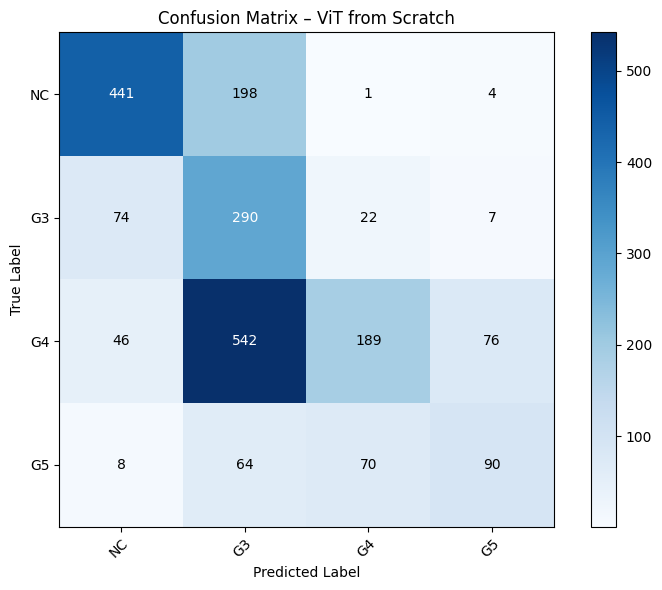

In [116]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 6))

# Blues heatmap
im = ax.imshow(cm, cmap="Blues", interpolation="nearest")
ax.figure.colorbar(im, ax=ax)

ax.set(
    xticks=np.arange(len(class_names)),
    yticks=np.arange(len(class_names)),
    xticklabels=class_names,
    yticklabels=class_names,
    xlabel="Predicted Label",
    ylabel="True Label",
    title="Confusion Matrix – ViT from Scratch"
)

plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

# Write counts on cells (white text on dark cells)
thresh = cm_scratch.max() / 2.0 if cm.max() > 0 else 0
for i in range(len(class_names)):
    for j in range(len(class_names)):
        ax.text(
            j, i, f"{cm[i, j]:d}",
            ha="center", va="center",
            color="white" if cm[i, j] > thresh else "black"
        )

plt.tight_layout()
plt.show()


In [117]:
# Build a model that gives us the encoded patch sequence and final predictions
encoder_layer = vit_model.get_layer("encoded_sequence")

grad_model = keras.Model(
    inputs=vit_model.inputs,
    outputs=[encoder_layer.output, vit_model.output],
)


In [118]:
def vit_gradcam(image, class_index=None):
    """
    image: (224, 224, 3) float32 in [0,1]
    class_index: which class to explain. If None, uses predicted class.
    """
    img_batch = np.expand_dims(image, axis=0).astype("float32")

    with tf.GradientTape() as tape:
        sequence_output, preds = grad_model(img_batch, training=False)

        # IMPORTANT: tell TF we want gradients wrt sequence_output
        tape.watch(sequence_output)

        if class_index is None:
            class_index = int(tf.argmax(preds[0]).numpy())

        class_score = preds[:, class_index]  # shape (1,)

    grads = tape.gradient(class_score, sequence_output)  # (1, num_patches, dim)

    # Remove batch dim
    grads = grads[0]            # (num_patches, dim)
    seq  = sequence_output[0]   # (num_patches, dim)

    # Patch importance: average gradient over embedding dim (simple attribution)
    weights = tf.reduce_mean(grads, axis=-1)  # (num_patches,)

    cam = weights.numpy()

    # Reshape to patch grid
    side = int(np.sqrt(cam.shape[0]))
    cam = cam.reshape((side, side))

    # Normalize [0,1]
    cam = cam - cam.min()
    if cam.max() > 1e-8:
        cam = cam / cam.max()

    # Upsample to image size
    cam = tf.image.resize(cam[..., np.newaxis], (IMG_SIZE, IMG_SIZE), method="bilinear")
    cam = cam.numpy().squeeze()

    return cam, class_index


In [119]:
import numpy as np
import matplotlib.pyplot as plt

def show_vit_gradcam(image, cam, alpha=0.35, title="Grad-CAM", cmap="jet"):
    """
    image: (H,W,3) in [0,1]
    cam: (H,W) in [0,1]
    """
    img = np.clip(image, 0, 1)
    cam = np.clip(cam, 0, 1)

    # Convert CAM -> colored heatmap (RGB)
    heatmap = plt.cm.get_cmap(cmap)(np.uint8(255 * cam))[:, :, :3]

    # Overlay
    overlay = (1 - alpha) * img + alpha * heatmap
    overlay = np.clip(overlay, 0, 1)

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(img)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(overlay)
    plt.title(title)
    plt.axis("off")

    plt.tight_layout()
    plt.show()


Picked indices per class: {'NC': 1478, 'G3': 170, 'G4': 0, 'G5': 111}


/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_725']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/tmp/ipykernel_47/2822540662.py:13: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  heatmap = plt.cm.get_cmap(cmap)(np.uint8(255 * cam))[:, :, :3]


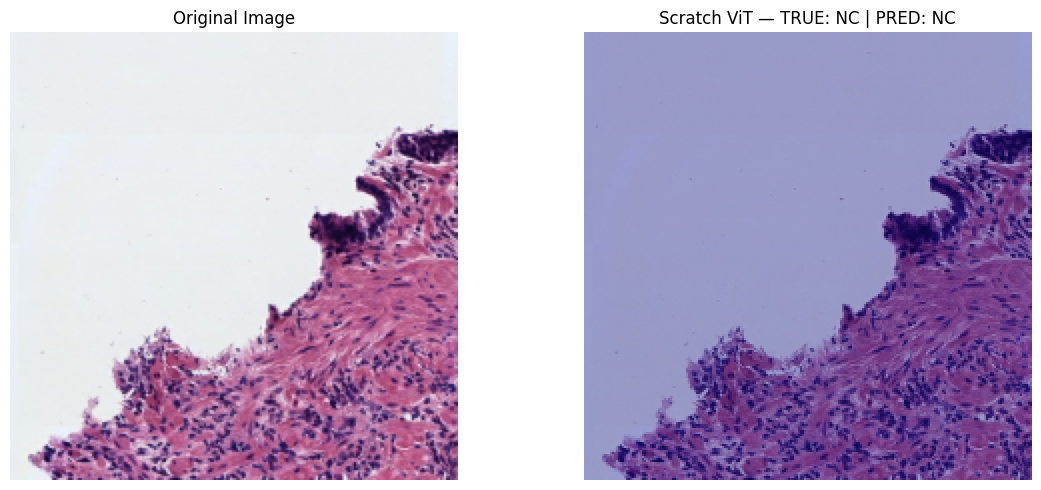

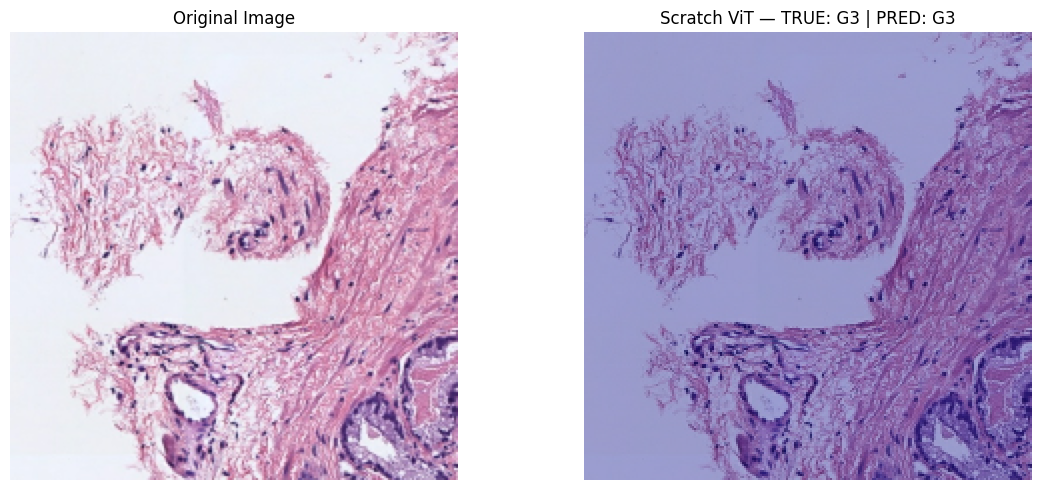

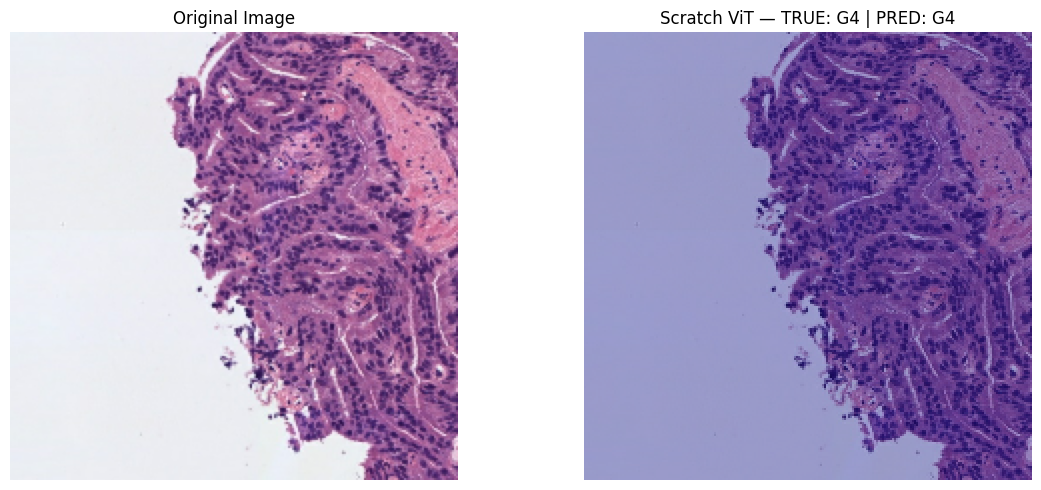

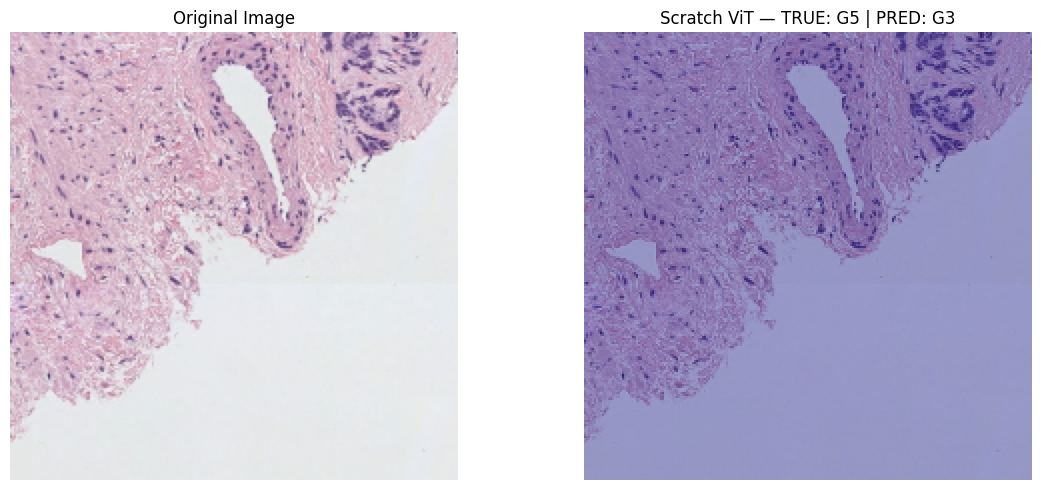

In [120]:
import numpy as np
import tensorflow as tf

# Collect all test images/labels once
X_list, y_list = [], []
for images, labels in test_ds:
    X_list.append(images.numpy())
    y_list.append(labels.numpy())

X_all = np.concatenate(X_list, axis=0)  # (N,224,224,3)
y_all = np.concatenate(y_list, axis=0)  # (N,)

# Pick first occurrence for each true class
picked = {}
for idx, y in enumerate(y_all):
    y = int(y)
    if y not in picked:
        picked[y] = idx
    if len(picked) == num_classes:
        break

print("Picked indices per class:", {class_names[k]: picked.get(k, None) for k in range(num_classes)})

# Show one Grad-CAM per class
for k in range(num_classes):
    if k not in picked:
        continue

    idx = picked[k]
    image = X_all[idx]

    pred_probs = vit_model.predict(image[None, ...], verbose=0)
    pred_label = int(np.argmax(pred_probs[0]))

    cam, _ = vit_gradcam(image, class_index=pred_label)

    title = f"Scratch ViT — TRUE: {class_names[k]} | PRED: {class_names[pred_label]}"
    show_vit_gradcam(image, cam, alpha=0.35, title=title)


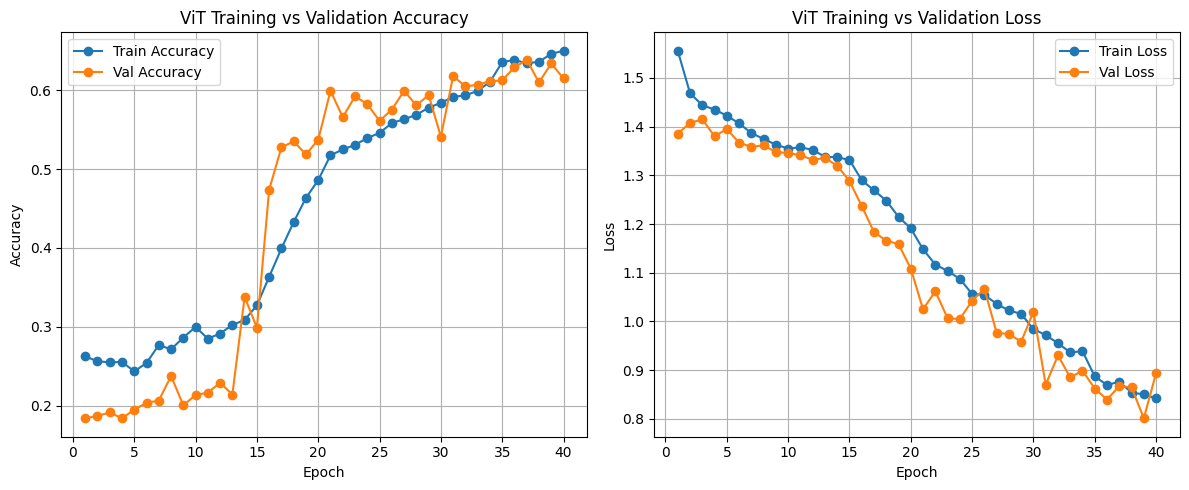

In [121]:
import matplotlib.pyplot as plt

# Get history data
hist = history.history
acc = hist["accuracy"]
val_acc = hist["val_accuracy"]
loss = hist["loss"]
val_loss = hist["val_loss"]

epochs = range(1, len(acc) + 1)

plt.figure(figsize=(12, 5))

# ---- Accuracy plot ----
plt.subplot(1, 2, 1)
plt.plot(epochs, acc, marker="o", label="Train Accuracy")
plt.plot(epochs, val_acc, marker="o", label="Val Accuracy")
plt.title("ViT Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# ---- Loss plot ----
plt.subplot(1, 2, 2)
plt.plot(epochs, loss, marker="o", label="Train Loss")
plt.plot(epochs, val_loss, marker="o", label="Val Loss")
plt.title("ViT Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()

# Optional: save high-res figure for your report
plt.savefig("vit_training_curves.png", dpi=300, bbox_inches="tight")

plt.show()


In [122]:
# import matplotlib.pyplot as plt

# # Accuracy
# plt.figure(figsize=(6,4))
# plt.plot(history.history["accuracy"], label="Train acc")
# plt.plot(history.history["val_accuracy"], label="Val acc")
# plt.xlabel("Epoch")
# plt.ylabel("Accuracy")
# plt.title("ViT (5-class) – Accuracy")
# plt.legend()
# plt.tight_layout()
# plt.show()

# # Loss
# plt.figure(figsize=(6,4))
# plt.plot(history.history["loss"], label="Train loss")
# plt.plot(history.history["val_loss"], label="Val loss")
# plt.xlabel("Epoch")
# plt.ylabel("Loss")
# plt.title("ViT (5-class) – Loss")
# plt.legend()
# plt.tight_layout()
# plt.show()


In [123]:
# from vit_keras import vit
# from tensorflow import keras
# from tensorflow.keras import layers

# # Pretrained ViT-B/16 backbone (ImageNet pretraining)
# base_vit = vit.vit_b16(
#     image_size=IMG_SIZE,      # 224
#     pretrained=True,          # use ImageNet pretrained weights
#     include_top=False,        # we will add our own head
#     pretrained_top=False,     # ignore the original classifier head
# )

# # Freeze backbone for initial training
# for layer in base_vit.layers:
#     layer.trainable = False

# # Build classification head on top
# inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
# x = inputs
# # (images are already resized & scaled to [0,1] in df_to_dataset)
# x = base_vit(x, training=False)   # (batch_size, feature_dim)
# x = layers.Dense(256, activation="relu")(x)
# x = layers.Dropout(0.5)(x)
# outputs = layers.Dense(num_classes, activation="softmax", name="predictions")(x)

# vit_pre_model = keras.Model(inputs=inputs, outputs=outputs, name="vit_b16_pretrained")
# vit_pre_model.summary()
from vit_keras import vit
from tensorflow import keras
from tensorflow.keras import layers

base_vit = vit.vit_b16(
    image_size=IMG_SIZE,
    pretrained=True,
    include_top=False,
    pretrained_top=False,
)

# Freeze backbone first (stage 1)
for layer in base_vit.layers:
    layer.trainable = False

inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

# Your pipeline gives [0,1]. Map it closer to common ViT pretraining range [-1,1]
x = layers.Lambda(lambda t: (t * 2.0) - 1.0, name="vit_preprocess")(inputs)

x = base_vit(x, training=False)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(num_classes, activation="softmax", name="predictions")(x)

vit_pre_model = keras.Model(inputs=inputs, outputs=outputs, name="vit_b16_pretrained")
vit_pre_model.summary()


/usr/local/lib/python3.11/dist-packages/vit_keras/utils.py:85: UserWarning: Resizing position embeddings from 24, 24 to 14, 14
  warnings.warn(


Model: "vit_b16_pretrained"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_50 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vit_preprocess (Lambda)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vit-b16 (Functional)            │ (None, 768)            │    85,798,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_116 (Dense)               │ (None, 256)            │       196,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_272 (Dropout)           │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 85,996,548 (328.05 MB)

 Trainable params: 197,892 (773.02 KB)

 Non-trainable params: 85,798,656 (327.30 MB)

In [124]:
# learning_rate_pre = 1e-4  # you can keep this the same as scratch

# vit_pre_model.compile(
#     optimizer=keras.optimizers.Adam(learning_rate=learning_rate_pre),
#     loss=keras.losses.SparseCategoricalCrossentropy(),
#     metrics=["accuracy"],
# )


In [125]:
from tensorflow import keras

def make_callbacks():
    return [
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True,
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=3,
            min_lr=1e-6,
        ),
    ]

# -----------------------
# Stage 1: Train head only (backbone frozen)
# -----------------------
for layer in base_vit.layers:
    layer.trainable = False

vit_pre_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

EPOCHS_FROZEN = 10
history_pre_frozen = vit_pre_model.fit(
    train_ds,
    epochs=EPOCHS_FROZEN,
    validation_data=val_ds,
    callbacks=make_callbacks(),
    class_weight=class_weights,
)

# -----------------------
# Stage 2: Fine-tuning (unfreeze last layers)
# -----------------------
for layer in base_vit.layers:
    layer.trainable = True

# Fine-tune only the last chunk (adjust 40 to 20/60 depending on overfitting)
for layer in base_vit.layers[:-40]:
    layer.trainable = False

vit_pre_model.compile(
    optimizer=keras.optimizers.AdamW(learning_rate=1e-5, weight_decay=1e-6),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

EPOCHS_FINE = 10
history_pre_finetune = vit_pre_model.fit(
    train_ds,
    epochs=EPOCHS_FINE,
    validation_data=val_ds,
    callbacks=make_callbacks(),
    class_weight=class_weights,
)


Epoch 1/10
249/249 ━━━━━━━━━━━━━━━━━━━━ 117s 345ms/step - accuracy: 0.5295 - loss: 1.1235 - val_accuracy: 0.7405 - val_loss: 0.6333 - learning_rate: 0.0010
Epoch 2/10
249/249 ━━━━━━━━━━━━━━━━━━━━ 62s 248ms/step - accuracy: 0.6730 - loss: 0.7775 - val_accuracy: 0.7475 - val_loss: 0.6116 - learning_rate: 0.0010
Epoch 3/10
249/249 ━━━━━━━━━━━━━━━━━━━━ 62s 248ms/step - accuracy: 0.7166 - loss: 0.6936 - val_accuracy: 0.7535 - val_loss: 0.6053 - learning_rate: 0.0010
Epoch 4/10
249/249 ━━━━━━━━━━━━━━━━━━━━ 62s 247ms/step - accuracy: 0.7287 - loss: 0.6567 - val_accuracy: 0.7364 - val_loss: 0.6192 - learning_rate: 0.0010
Epoch 5/10
249/249 ━━━━━━━━━━━━━━━━━━━━ 62s 248ms/step - accuracy: 0.7327 - loss: 0.6462 - val_accuracy: 0.7801 - val_loss: 0.5484 - learning_rate: 0.0010
Epoch 6/10
249/249 ━━━━━━━━━━━━━━━━━━━━ 62s 247ms/step - accuracy: 0.7418 - loss: 0.6391 - val_accuracy: 0.7495 - val_loss: 0.6067 - learning_rate: 0.0010
Epoch 7/10
249/249 ━━━━━━━━━━━━━━━━━━━━ 62s 247ms/step - accuracy: 0.

In [126]:
import numpy as np
import matplotlib.pyplot as plt

from collections import Counter
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    roc_auc_score,
    cohen_kappa_score
)

def collect_y_true(ds):
    y_true = []
    for _, y in ds:
        y_true.append(y.numpy().reshape(-1))
    return np.concatenate(y_true)

def evaluate_model(model, ds, class_names, title="Model"):
    num_classes = len(class_names)

    # y_true
    y_true = collect_y_true(ds)

    # y_prob / y_pred
    y_prob = model.predict(ds, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)

    print(f"\n===== {title} =====")
    print("y_true counts:", {class_names[k]: v for k, v in sorted(Counter(y_true).items())})
    print("y_pred counts:", {class_names[k]: v for k, v in sorted(Counter(y_pred).items())})

    # Core metrics
    acc = accuracy_score(y_true, y_pred)
    qwk = cohen_kappa_score(y_true, y_pred, weights="quadratic")

    # Multiclass AUC (OvR). Needs at least 2 classes present in y_true.
    auc = None
    try:
        auc = roc_auc_score(
            y_true,
            y_prob,
            multi_class="ovr",
            average="macro"
        )
    except Exception as e:
        print("AUC not computed (usually because a class is missing in y_true):", e)

    print(f"Accuracy: {acc:.4f}")
    print(f"QWK:      {qwk:.4f}")
    if auc is not None:
        print(f"AUC(OVR, macro): {auc:.4f}")

    # Classification report (force fixed label order 0..K-1)
    print("\nClassification Report:")
    print(classification_report(
        y_true, y_pred,
        labels=np.arange(num_classes),
        target_names=class_names,
        digits=4,
        zero_division=0
    ))

    # Confusion matrix (always KxK)
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(num_classes))


    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

    plt.figure(figsize=(7, 6))
    disp.plot(values_format="d", cmap=None)
    plt.title(f"Confusion Matrix — {title}")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

    return {"acc": acc, "qwk": qwk, "auc": auc, "cm": cm}


y_true counts: {'NC': 644, 'G3': 393, 'G4': 853, 'G5': 232}
y_pred counts: {'NC': 735, 'G3': 485, 'G4': 738, 'G5': 164}

=== Test Metrics (Pretrained ViT) ===
Accuracy:         0.7215
Macro Precision:  0.6821
Macro Recall:     0.6739
Macro F1-score:   0.6707
AUC (OvR, macro): 0.9074
QWK:              0.7965

Confusion matrix (fixed order):
 [[611  28   5   0]
 [ 65 263  61   4]
 [ 46 186 559  62]
 [ 13   8 113  98]]


<Figure size 700x600 with 0 Axes>

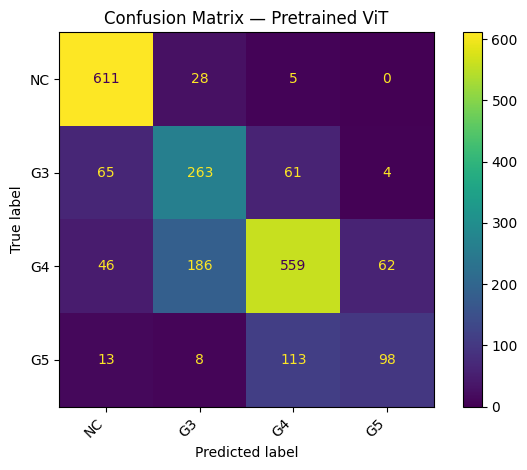


Classification report:

              precision    recall  f1-score   support

          NC     0.8313    0.9488    0.8861       644
          G3     0.5423    0.6692    0.5991       393
          G4     0.7575    0.6553    0.7027       853
          G5     0.5976    0.4224    0.4949       232

    accuracy                         0.7215      2122
   macro avg     0.6821    0.6739    0.6707      2122
weighted avg     0.7225    0.7215    0.7165      2122



In [127]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from collections import Counter
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    cohen_kappa_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)

# ---- Collect predictions on test set ----
y_true = []
y_prob = []

for images, labels in test_ds:
    probs = vit_pre_model.predict(images, verbose=0)
    y_prob.append(probs)
    y_true.append(labels.numpy())

y_prob = np.concatenate(y_prob, axis=0)   # (N, num_classes)
y_true = np.concatenate(y_true, axis=0)   # (N,)
y_pred = y_prob.argmax(axis=1)            # (N,)

# ---- Sanity checks: counts per class ----
print("y_true counts:", {class_names[k]: v for k, v in sorted(Counter(y_true).items())})
print("y_pred counts:", {class_names[k]: v for k, v in sorted(Counter(y_pred).items())})

# ---- Metrics ----
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average="macro", zero_division=0)
recall = recall_score(y_true, y_pred, average="macro", zero_division=0)
f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)

# AUC (multi-class OvR) — this can fail if a class is missing in y_true
auc = None
try:
    y_true_onehot = tf.keras.utils.to_categorical(y_true, num_classes=num_classes)
    auc = roc_auc_score(y_true_onehot, y_prob, multi_class="ovr", average="macro")
except Exception as e:
    print("AUC not computed (often because a class is missing in y_true):", e)

qwk = cohen_kappa_score(y_true, y_pred, weights="quadratic")

print("\n=== Test Metrics (Pretrained ViT) ===")
print(f"Accuracy:         {accuracy:.4f}")
print(f"Macro Precision:  {precision:.4f}")
print(f"Macro Recall:     {recall:.4f}")
print(f"Macro F1-score:   {f1:.4f}")
if auc is not None:
    print(f"AUC (OvR, macro): {auc:.4f}")
print(f"QWK:              {qwk:.4f}")

# ---- Confusion Matrix (FORCE 5x5) ----
labels_fixed = np.arange(num_classes)  # [0,1,2,3,4]
cm = confusion_matrix(y_true, y_pred, labels=labels_fixed)
cm_pretrained = cm.copy()


print("\nConfusion matrix (fixed order):\n", cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
plt.figure(figsize=(7,6))
disp.plot(values_format="d", cmap=None)
plt.title("Confusion Matrix — Pretrained ViT")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# ---- Classification report (FORCE all 5 labels) ----
print("\nClassification report:\n")
print(classification_report(
    y_true, y_pred,
    labels=labels_fixed,
    target_names=class_names,
    digits=4,
    zero_division=0
))


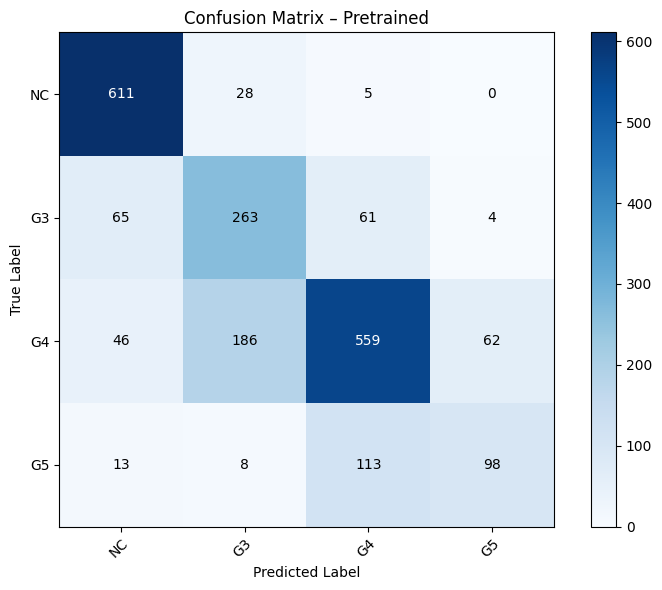

In [136]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 6))

# Blues heatmap
im = ax.imshow(cm, cmap="Blues", interpolation="nearest")
ax.figure.colorbar(im, ax=ax)

ax.set(
    xticks=np.arange(len(class_names)),
    yticks=np.arange(len(class_names)),
    xticklabels=class_names,
    yticklabels=class_names,
    xlabel="Predicted Label",
    ylabel="True Label",
    title="Confusion Matrix – Pretrained"
)

plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

# Write counts on cells (white text on dark cells)
thresh = cm_pretrained.max() / 2.0 if cm.max() > 0 else 0
for i in range(len(class_names)):
    for j in range(len(class_names)):
        ax.text(
            j, i, f"{cm[i, j]:d}",
            ha="center", va="center",
            color="white" if cm[i, j] > thresh else "black"
        )

plt.tight_layout()
plt.show()


In [129]:
import tensorflow as tf

# 1) Get base_vit (use your existing variable if you have it)
# If you already have `base_vit` defined, keep this as-is.
try:
    base_vit
except NameError:
    # fallback: find the first nested Model (usually the backbone)
    base_vit = next(l for l in vit_pre_model.layers if isinstance(l, tf.keras.Model))

# 2) Find the patch-embedding conv layer inside base_vit (yours is named "embedding")
embed_conv = base_vit.get_layer("embedding")  # Conv2D
base_vit_with_embed = tf.keras.Model(
    inputs=base_vit.inputs,
    outputs=[embed_conv.output, base_vit.output],
    name="base_vit_with_embed"
)

# 3) Rebuild the outer forward pass up to preds, but now we also capture conv activations
# Try to use your preprocessing layer if it exists
inputs0 = vit_pre_model.inputs[0] if isinstance(vit_pre_model.inputs, (list, tuple)) else vit_pre_model.inputs

try:
    preprocess_layer = vit_pre_model.get_layer("vit_preprocess")  # your Lambda: (x*2 - 1)
    x = preprocess_layer(inputs0)
except Exception:
    x = inputs0  # if you didn't have a preprocess layer inside the model

conv_out, feats = base_vit_with_embed(x, training=False)

# Now apply the "head" layers that come AFTER base_vit in vit_pre_model
# This reuses your exact trained layers (Dropout/Dense/etc.)
x_head = feats
seen_backbone = False
for layer in vit_pre_model.layers:
    if layer == base_vit:
        seen_backbone = True
        continue
    if not seen_backbone:
        continue
    # skip InputLayer
    if isinstance(layer, tf.keras.layers.InputLayer):
        continue
    try:
        x_head = layer(x_head, training=False)
    except TypeError:
        x_head = layer(x_head)

preds = x_head

# Final CAM model: same input as vit_pre_model, outputs conv activations + predictions
vit_pre_model_cam = tf.keras.Model(
    inputs=vit_pre_model.inputs,
    outputs=[conv_out, preds],
    name="vit_pre_model_cam"
)

print("Built vit_pre_model_cam ✓")
print("CAM outputs shapes:", vit_pre_model_cam.output[0].shape, vit_pre_model_cam.output[1].shape)


Built vit_pre_model_cam ✓
CAM outputs shapes: (None, 14, 14, 768) (None, 4)


In [130]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

def pack_inputs(model, x):
    # vit_pre_model usually has inputs as a list of length 1
    if isinstance(model.inputs, (list, tuple)) and len(model.inputs) == 1:
        return [x]
    return x

def make_gradcam_heatmap_cam(cam_model, img_tensor, class_index=None):
    """
    cam_model outputs: [conv_out, preds]
    img_tensor: (1,H,W,3)
    """
    with tf.GradientTape() as tape:
        conv_out, preds = cam_model(pack_inputs(cam_model, img_tensor), training=False)
        if class_index is None:
            class_index = tf.argmax(preds[0])
        score = preds[:, class_index]

    grads = tape.gradient(score, conv_out)               # (1,h,w,c)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2)) # (c,)
    conv_out = conv_out[0]                               # (h,w,c)

    heatmap = tf.reduce_sum(conv_out * pooled_grads, axis=-1)  # (h,w)
    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

    return heatmap.numpy(), int(class_index.numpy())

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

def show_gradcam(img, heatmap, alpha=0.35, title="Grad-CAM", cmap="jet"):
    """
    img: (H,W,3) in [0,1]
    heatmap: (h,w) in [0,1]
    """
    img = np.clip(img, 0, 1)

    # resize heatmap to image size
    H, W = img.shape[:2]
    heatmap_resized = tf.image.resize(heatmap[..., None], (H, W)).numpy().squeeze()
    heatmap_resized = np.clip(heatmap_resized, 0, 1)

    # convert heatmap -> RGB using colormap
    heatmap_rgb = plt.cm.get_cmap(cmap)(np.uint8(255 * heatmap_resized))[:, :, :3]

    # overlay (blend)
    overlay = (1 - alpha) * img + alpha * heatmap_rgb
    overlay = np.clip(overlay, 0, 1)

    # plot side-by-side (same as teammate)
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(img)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(overlay)
    plt.title(title)
    plt.axis("off")

    plt.tight_layout()
    plt.show()


In [131]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import roc_curve, auc, roc_auc_score

def collect_y_true(ds):
    ys = []
    for _, y in ds:
        ys.append(y.numpy().reshape(-1))
    return np.concatenate(ys)

def plot_multiclass_roc(model, ds, class_names, title="ROC"):
    num_classes = len(class_names)

    # True labels
    y_true = collect_y_true(ds).astype(int)

    # Predicted probabilities (N, K)
    y_prob = model.predict(ds, verbose=0)
    assert y_prob.shape[1] == num_classes, (y_prob.shape, num_classes)

    # One-hot for ROC
    y_true_oh = tf.keras.utils.to_categorical(y_true, num_classes=num_classes)

    # Macro AUC (can fail if a class is missing in y_true)
    macro_auc = None
    try:
        macro_auc = roc_auc_score(y_true_oh, y_prob, multi_class="ovr", average="macro")
    except Exception as e:
        print(f"[{title}] Macro AUC not computed (often missing class in y_true): {e}")

    # Plot per-class ROC
    plt.figure(figsize=(7, 6))

    aucs = {}
    for i, name in enumerate(class_names):
        # Skip if class not present in y_true
        positives = int(y_true_oh[:, i].sum())
        if positives == 0:
            print(f"[{title}] Skipping {name}: no positive samples in y_true")
            continue
        if positives == len(y_true):
            print(f"[{title}] Skipping {name}: all samples are this class in y_true")
            continue

        fpr, tpr, _ = roc_curve(y_true_oh[:, i], y_prob[:, i])
        roc_auc = auc(fpr, tpr)
        aucs[name] = roc_auc
        plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc:.3f})")

    # Chance line
    plt.plot([0, 1], [0, 1], linestyle="--")

    plt.title(f"{title}" + (f" | Macro AUC={macro_auc:.3f}" if macro_auc is not None else ""))
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # Print AUCs
    print(f"\n[{title}] Per-class AUCs:")
    for k, v in aucs.items():
        print(f"  {k}: {v:.4f}")
    if macro_auc is not None:
        print(f"[{title}] Macro AUC (OvR): {macro_auc:.4f}")

    return {"per_class_auc": aucs, "macro_auc": macro_auc}


In [132]:
import numpy as np

# 1) Collect all test images + labels (simple approach; OK if test set isn't huge)
X_list, y_list = [], []
for images, labels in test_ds:
    X_list.append(images.numpy())
    y_list.append(labels.numpy())

X_all = np.concatenate(X_list, axis=0)  # (N,H,W,3)
y_all = np.concatenate(y_list, axis=0)  # (N,)

# 2) Pick one index per true label
picked = {}  # label -> index
for idx, y in enumerate(y_all):
    y = int(y)
    if y not in picked:
        picked[y] = idx
    if len(picked) == num_classes:
        break

print("Picked indices per class:")
for k in range(num_classes):
    if k in picked:
        print(f"{k} ({class_names[k]}): index {picked[k]}")
    else:
        print(f"{k} ({class_names[k]}): MISSING in test set (no true samples)")


Picked indices per class:
0 (NC): index 1478
1 (G3): index 170
2 (G4): index 0
3 (G5): index 111


/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_810']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/tmp/ipykernel_47/2180241805.py:49: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  heatmap_rgb = plt.cm.get_cmap(cmap)(np.uint8(255 * heatmap_resized))[:, :, :3]


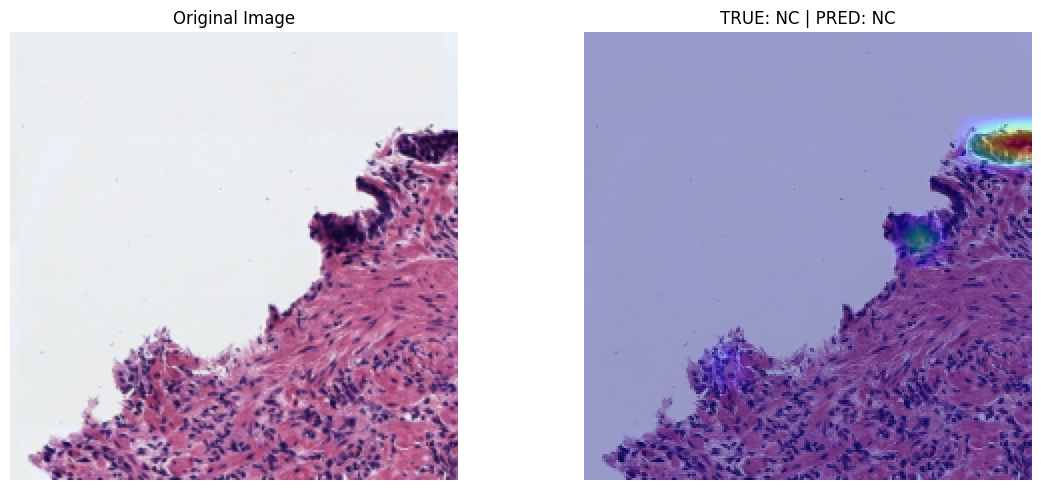

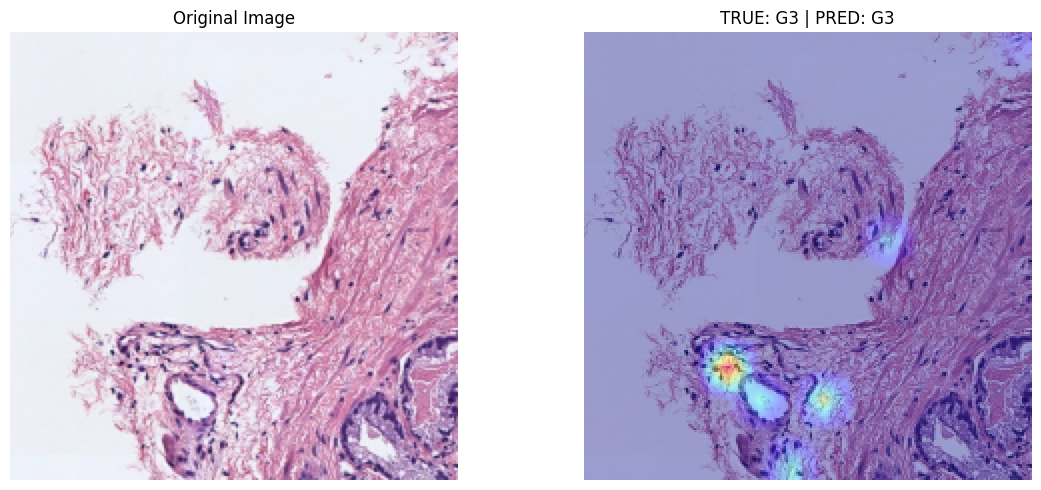

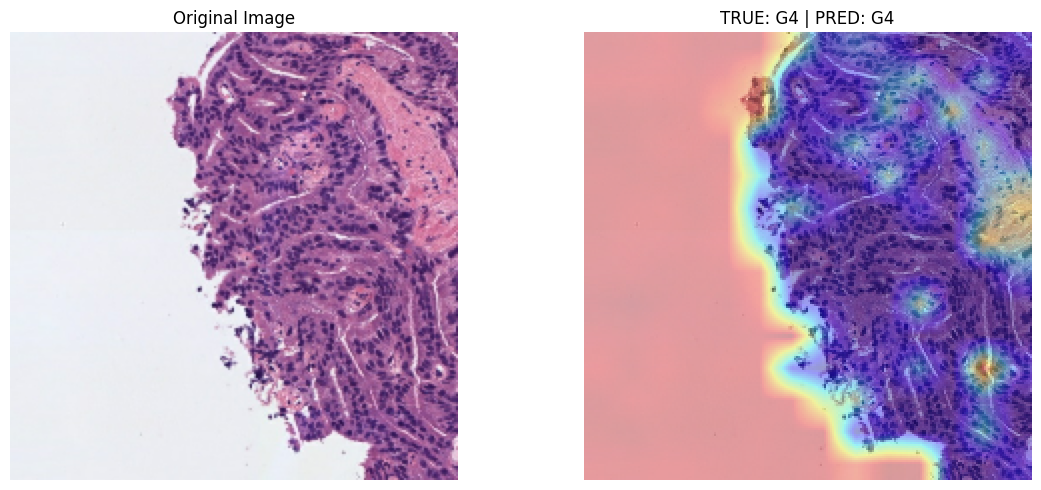

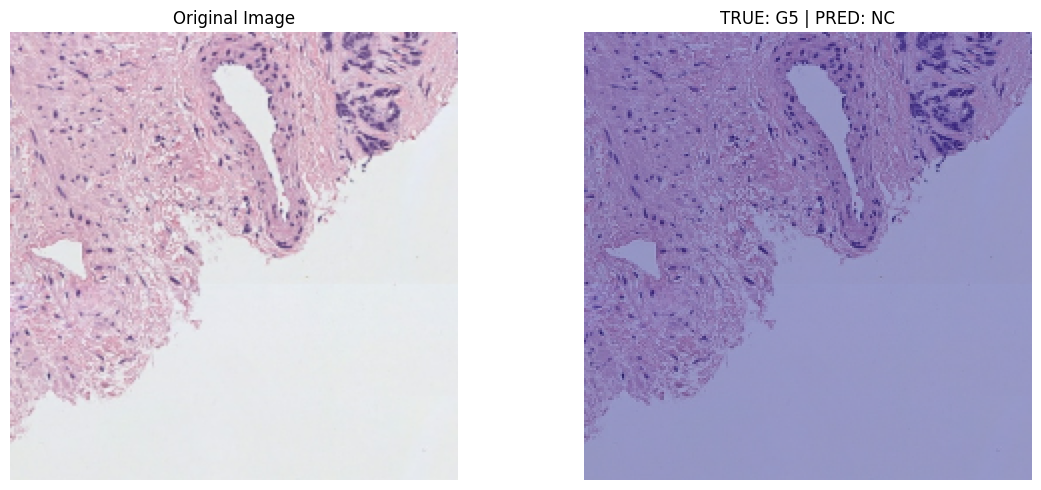

In [133]:
import tensorflow as tf

for k in range(num_classes):
    if k not in picked:
        continue

    idx = picked[k]
    img = X_all[idx]  # (H,W,3) in [0,1]
    img_tensor = tf.expand_dims(tf.convert_to_tensor(img, dtype=tf.float32), axis=0)

    heatmap, pred_idx = make_gradcam_heatmap_cam(vit_pre_model_cam, img_tensor)

    title = f"TRUE: {class_names[k]} | PRED: {class_names[pred_idx]}"
    show_gradcam(img, heatmap, title=title)

probs = vit_pre_model.predict(img_tensor, verbose=0)[0]
pred_idx = int(np.argmax(probs))
conf = float(np.max(probs))
title = f"TRUE: {class_names[k]} | PRED: {class_names[pred_idx]} ({conf:.2f})"



In [134]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import roc_curve, auc, roc_auc_score

def collect_y_true(ds):
    ys = []
    for _, y in ds:
        ys.append(y.numpy().reshape(-1))
    return np.concatenate(ys)

def plot_multiclass_roc(model, ds, class_names, title="ROC"):
    num_classes = len(class_names)

    # True labels
    y_true = collect_y_true(ds).astype(int)

    # Predicted probabilities (N, K)
    y_prob = model.predict(ds, verbose=0)
    assert y_prob.shape[1] == num_classes, (y_prob.shape, num_classes)

    # One-hot for ROC
    y_true_oh = tf.keras.utils.to_categorical(y_true, num_classes=num_classes)

    # Macro AUC (can fail if a class is missing in y_true)
    macro_auc = None
    try:
        macro_auc = roc_auc_score(y_true_oh, y_prob, multi_class="ovr", average="macro")
    except Exception as e:
        print(f"[{title}] Macro AUC not computed (often missing class in y_true): {e}")

    # Plot per-class ROC
    plt.figure(figsize=(7, 6))

    aucs = {}
    for i, name in enumerate(class_names):
        # Skip if class not present in y_true
        positives = int(y_true_oh[:, i].sum())
        if positives == 0:
            print(f"[{title}] Skipping {name}: no positive samples in y_true")
            continue
        if positives == len(y_true):
            print(f"[{title}] Skipping {name}: all samples are this class in y_true")
            continue

        fpr, tpr, _ = roc_curve(y_true_oh[:, i], y_prob[:, i])
        roc_auc = auc(fpr, tpr)
        aucs[name] = roc_auc
        plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc:.3f})")

    # Chance line
    plt.plot([0, 1], [0, 1], linestyle="--")

    plt.title(f"{title}" + (f" | Macro AUC={macro_auc:.3f}" if macro_auc is not None else ""))
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # Print AUCs
    print(f"\n[{title}] Per-class AUCs:")
    for k, v in aucs.items():
        print(f"  {k}: {v:.4f}")
    if macro_auc is not None:
        print(f"[{title}] Macro AUC (OvR): {macro_auc:.4f}")

    return {"per_class_auc": aucs, "macro_auc": macro_auc}


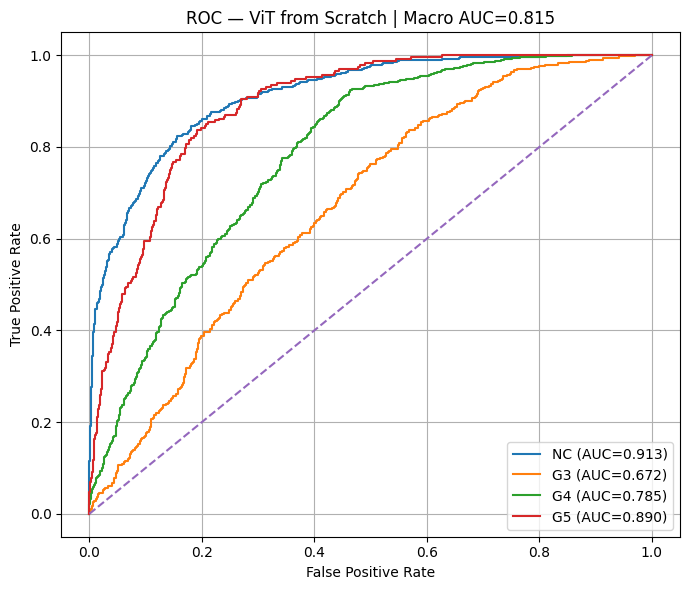


[ROC — ViT from Scratch] Per-class AUCs:
  NC: 0.9130
  G3: 0.6718
  G4: 0.7850
  G5: 0.8902
[ROC — ViT from Scratch] Macro AUC (OvR): 0.8150


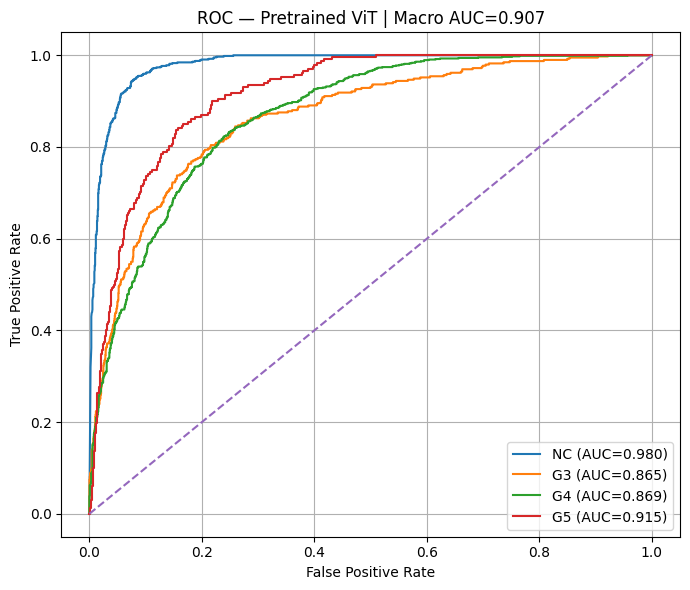


[ROC — Pretrained ViT] Per-class AUCs:
  NC: 0.9798
  G3: 0.8647
  G4: 0.8694
  G5: 0.9155
[ROC — Pretrained ViT] Macro AUC (OvR): 0.9074


In [135]:
# Scratch ViT
scratch_roc = plot_multiclass_roc(
    vit_model,
    test_ds,
    class_names,
    title="ROC — ViT from Scratch"
)

# Pretrained ViT
pretrained_roc = plot_multiclass_roc(
    vit_pre_model,
    test_ds,
    class_names,
    title="ROC — Pretrained ViT"
)


NameError: name 'plot_multiclass_roc' is not defined

In [ ]:
cm